# **Consumer Shopping Behavior Analysis: A Multivariate Statistical Investigation**

---

## Declaration

I hereby declare that this project is my original work and has not been submitted elsewhere for any academic purpose. All data, references, and analytical outputs have been properly cited and acknowledged.

---

## Executive Summary

**Overview:** This study examines consumer shopping behavior using a dataset of 3,900 retail transactions across 16 variables. The research investigates the statistical relationships between demographic factors (age, gender), purchase patterns (amount, frequency, season), and behavioral outcomes (subscription status, product category preferences).

**Objectives:**
- Determine if significant differences exist in purchase amounts across gender and season.
- Examine associations between categorical variables such as gender, discount usage, and subscription status.
- Reduce dimensionality and extract latent factors from numeric shopping variables.
- Segment customers into meaningful behavioral clusters.
- Predict subscription status (binary) using Logistic Regression.
- Classify product category (multi-group) using Discriminant Analysis.

**Methodology:** Independent samples T-Test, One-Way ANOVA, Chi-Square Test of Independence, Principal Component Analysis (PCA), Exploratory Factor Analysis (EFA), K-Means Clustering, Logistic Regression, and Linear Discriminant Analysis (LDA).

**Key Findings:** No significant gender differences in purchase amount were found; season does not significantly affect purchase amount; gender and subscription status are significantly associated; PCA reduced four numeric variables to two meaningful components; three distinct customer clusters emerged; logistic regression moderately predicts subscription status; LDA successfully separates product categories.

**Recommendation:** Retailers should focus marketing efforts on gender-based subscription campaigns and leverage seasonal promotions selectively, particularly targeting the identified high-value customer cluster.

---

## 1. Introduction

### 1.1 Background

Consumer behavior in retail has undergone a dramatic transformation in the digital age. Understanding the motivations, patterns, and preferences of shoppers is no longer a luxury but a strategic necessity for businesses aiming to optimize revenue, retention, and customer experience. With vast amounts of transactional data now available, statistical analysis provides a rigorous pathway to converting raw data into actionable insights.

### 1.2 Need for the Study

Despite abundant retail transaction data, many businesses fail to extract structured, hypothesis-driven insights from it. Key questions remain unanswered:

- Do demographic differences (age, gender) translate into meaningful differences in purchase behavior?
- Are subscription programs and discount usage associated with specific customer demographics?
- Can customers be meaningfully segmented based on behavioral metrics?
- What variables best predict whether a customer subscribes or the product category they purchase?

Addressing these questions with multivariate statistical techniques enables retailers to move from anecdotal decision-making to evidence-based strategies.

### 1.3 Importance of the Topic

Subscription-based retail models are growing globally, making it critical to understand what drives customers toward or away from subscriptions. Similarly, customer segmentation underpins targeted marketing, inventory planning, and personalized recommendations. This study bridges statistical rigor with practical retail strategy.

---

## 2. Literature Review

### 2.1 Theoretical Background

Consumer behavior theory, rooted in the works of Kotler & Keller (2016), posits that purchasing decisions are influenced by psychological, social, cultural, and situational factors. From a quantitative perspective, multivariate analysis allows researchers to simultaneously examine multiple variables and their interrelationships.

### 2.2 Concepts and Models Used

- **T-Test & ANOVA (Parametric Inference):** Student (1908) introduced the t-test for comparing means under small samples. Fisher (1925) extended this to ANOVA, enabling multi-group mean comparisons while controlling Type I error.
- **Chi-Square Test (Pearson, 1900):** The foundational test for examining statistical independence between two categorical variables.
- **Principal Component Analysis (PCA):** Pearson (1901) and Hotelling (1933) formalized PCA as a method to orthogonally transform correlated variables into uncorrelated principal components, retaining maximum variance.
- **Exploratory Factor Analysis (EFA):** Spearman's (1904) work on latent factors led to EFA, which identifies hidden constructs underlying observed variables.
- **K-Means Clustering:** MacQueen (1967) proposed K-Means as an iterative centroid-based algorithm for partitioning data into k groups.
- **Logistic Regression:** Cox (1958) developed logistic regression as a model for binary outcomes, estimating the probability of class membership.
- **Linear Discriminant Analysis (LDA):** Fisher (1936) introduced LDA to find linear combinations of features that maximally separate two or more classes.

### 2.3 Previous Studies Related to the Topic

- Verhoef et al. (2010) demonstrated that customer loyalty programs (subscriptions) are significantly associated with purchase frequency and spend.
- Grewal et al. (2009) found that seasonal promotions interact with demographic variables to influence purchase amounts.
- Chaffey & Ellis-Chadwick (2019) highlighted how PCA and clustering of behavioral variables help retailers build personalized recommendation engines.
- Hosmer & Lemeshow (2000) established logistic regression as the gold standard for binary outcome prediction in marketing research.

---

## 3. Research Objectives

1. To test whether mean purchase amounts differ significantly by **gender** (Independent T-Test).
2. To test whether mean purchase amounts differ significantly across **seasons** (One-Way ANOVA).
3. To examine whether **gender** and **subscription status** are statistically independent (Chi-Square).
4. To reduce the dimensionality of numeric shopping variables using **PCA**.
5. To extract latent behavioral constructs using **Exploratory Factor Analysis (EFA)**.
6. To **segment customers** into homogeneous behavioral groups using K-Means Clustering.
7. To **predict subscription status** (Yes/No) using Logistic Regression.
8. To **classify product category** (4 classes) using Linear Discriminant Analysis (LDA).

---

## 4. Research Methodology

### 4.1 Research Design
This study adopts a **descriptive and inferential quantitative research design**. The analysis is secondary in nature, using an existing transactional retail dataset.

### 4.2 Data Source
The dataset `shopping_behavior_updated.csv` is a publicly available retail transaction dataset containing **3,900 customer records** and **16 variables**. Variables span demographics (Age, Gender), transaction details (Purchase Amount, Category, Item Purchased), contextual factors (Season, Location, Color, Size), and behavioral indicators (Frequency of Purchases, Previous Purchases, Subscription Status, Discount Applied, Review Rating, Payment Method).

### 4.3 Data Cleaning Steps
- Checked for and confirmed **zero missing values** across all 16 variables.
- Verified data types: numeric variables (Age, Purchase Amount, Review Rating, Previous Purchases, Customer ID) and categorical variables (all others).
- `Customer ID` dropped from all analyses as it is a unique identifier with no analytical value.
- Binary categorical variables (Subscription Status, Discount Applied, Gender) encoded as 0/1 for regression and discriminant analyses.
- Ordinal-style frequency variable (`Frequency of Purchases`) label-encoded where required.

### 4.4 Statistical Hypotheses

| Analysis | H₀ | H₁ |
|---|---|---|
| T-Test | Mean purchase amount is equal for Male and Female | Mean purchase amount differs by gender |
| ANOVA | Mean purchase amount is equal across all seasons | At least one season has a different mean purchase amount |
| Chi-Square | Gender and Subscription Status are independent | Gender and Subscription Status are associated |
| Logistic Regression | Predictors do not explain subscription status | Predictors significantly explain subscription status |

### 4.5 Tools Used
Python 3 with libraries: `pandas`, `numpy`, `scipy`, `statsmodels`, `sklearn`, `factor_analyzer`, `matplotlib`, `seaborn`

---

## 5. Data Analysis & Interpretation

### 5.0 Setup & Data Loading

In [14]:
# ── Core Libraries ──────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Statistical Testing
import scipy.stats as stats

# Machine Learning
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_curve, roc_auc_score, ConfusionMatrixDisplay
)

# Factor Analysis

# Visualisation
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.family': 'sans-serif'
})
PALETTE = ['#2196F3', '#FF5722', '#4CAF50', '#9C27B0']

print("✓ All libraries loaded successfully")

✓ All libraries loaded successfully


In [15]:
# ── Load Dataset ─────────────────────────────────────────────────────────────
df = pd.read_csv("c:/Users/aeess/Downloads/shopping_behavior_updated (1).csv")
df.drop(columns=['Customer ID'], inplace=True)   # identifier; no analytical value

print(f"Dataset Shape : {df.shape}")
print(f"Missing Values: {df.isnull().sum().sum()}")
print("\nColumn Types:")
print(df.dtypes)

Dataset Shape : (3900, 15)
Missing Values: 0

Column Types:
Age                         int64
Gender                     object
Item Purchased             object
Category                   object
Purchase Amount (USD)       int64
Location                   object
Size                       object
Color                      object
Season                     object
Review Rating             float64
Subscription Status        object
Discount Applied           object
Previous Purchases          int64
Payment Method             object
Frequency of Purchases     object
dtype: object


In [16]:
# ── Descriptive Statistics ────────────────────────────────────────────────────
print("=== Descriptive Statistics (Numeric Variables) ===")
df.describe().round(2)

=== Descriptive Statistics (Numeric Variables) ===


,Age,Purchase Amount (USD),Review Rating,Previous Purchases
count,3900.00,3900.00,3900.00,3900.00
mean,44.07,59.76,3.75,25.35
std,15.21,23.69,0.72,14.45
min,18.00,20.00,2.50,1.00
25%,31.00,39.00,3.10,13.00
50%,44.00,60.00,3.70,25.00
75%,57.00,81.00,4.40,38.00
max,70.00,100.00,5.00,50.00


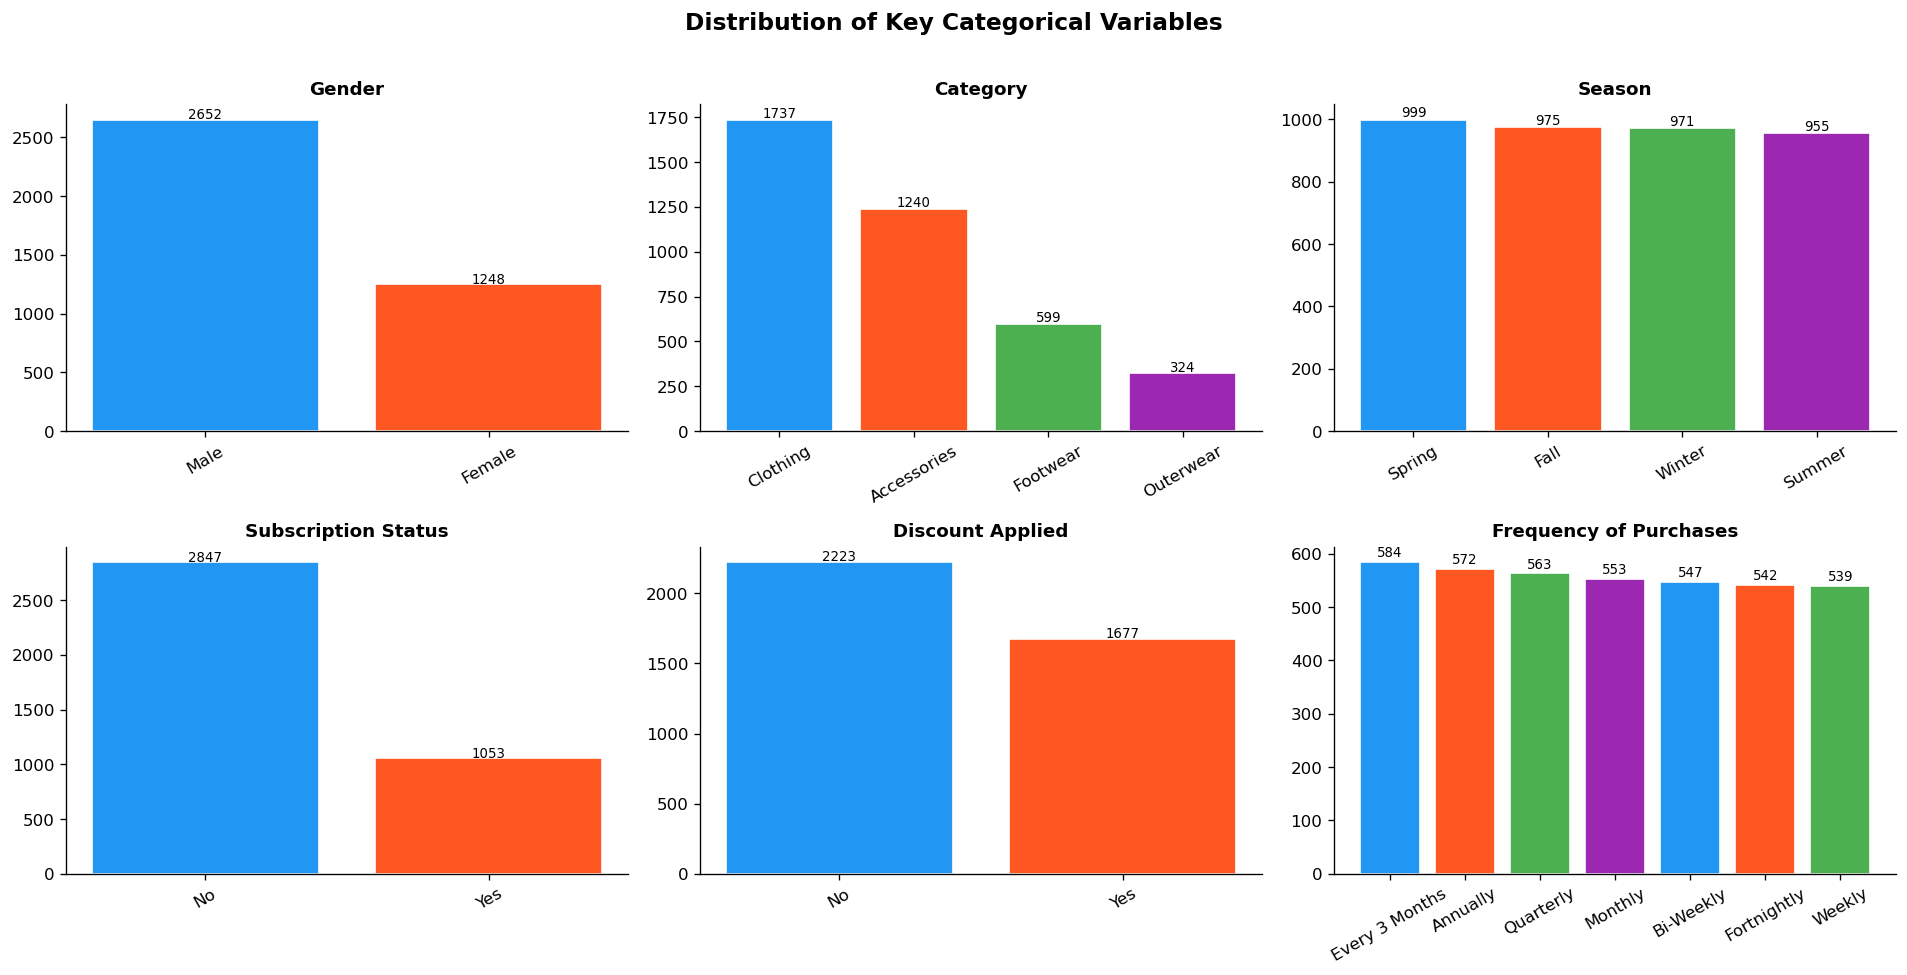

In [17]:
# ── Categorical Frequency Overview ───────────────────────────────────────────
cat_cols = ['Gender', 'Category', 'Season', 'Subscription Status',
            'Discount Applied', 'Frequency of Purchases']

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    counts = df[col].value_counts()
    axes[i].bar(counts.index, counts.values, color=PALETTE[:len(counts)], edgecolor='white')
    axes[i].set_title(col, fontweight='bold', fontsize=11)
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=30)
    for bar, val in zip(axes[i].patches, counts.values):
        axes[i].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
                     str(val), ha='center', fontsize=8)

fig.suptitle('Distribution of Key Categorical Variables', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

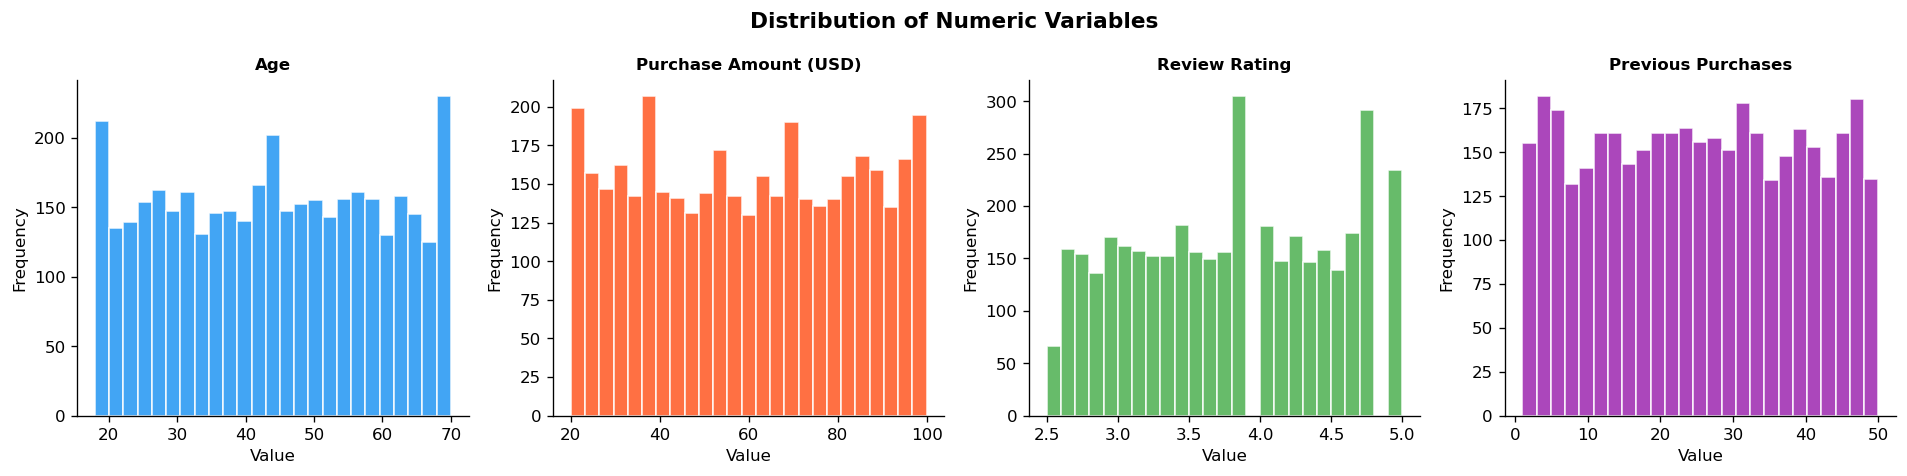

In [18]:
# ── Distribution of Numeric Variables ────────────────────────────────────────
num_cols = ['Age', 'Purchase Amount (USD)', 'Review Rating', 'Previous Purchases']

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for i, col in enumerate(num_cols):
    axes[i].hist(df[col], bins=25, color=PALETTE[i], edgecolor='white', alpha=0.85)
    axes[i].set_title(col, fontweight='bold', fontsize=10)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

fig.suptitle('Distribution of Numeric Variables', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
### 5.1 Independent Samples T-Test
**Research Question:** Does mean Purchase Amount differ significantly between Male and Female customers?

**H₀:** μ_Male = μ_Female (no difference in mean purchase amount)  
**H₁:** μ_Male ≠ μ_Female (significant difference exists)  
**Significance Level:** α = 0.05

In [19]:
# ── Independent Samples T-Test: Purchase Amount by Gender ────────────────────
male   = df[df['Gender'] == 'Male']['Purchase Amount (USD)']
female = df[df['Gender'] == 'Female']['Purchase Amount (USD)']

t_stat, p_value = stats.ttest_ind(male, female, equal_var=True)

print("Independent Samples T-Test: Purchase Amount by Gender")
print("=" * 52)
print(f"Male   — Mean: ${male.mean():.2f}, SD: {male.std():.2f}, n={len(male)}")
print(f"Female — Mean: ${female.mean():.2f}, SD: {female.std():.2f}, n={len(female)}")
print(f"\nt-statistic : {t_stat:.4f}")
print(f"p-value     : {p_value:.4f}")

if p_value < 0.05:
    print("\nDecision: REJECT H₀ — Significant difference in purchase amount by gender (p < 0.05)")
else:
    print("\nDecision: FAIL TO REJECT H₀ — No significant difference in purchase amount by gender (p ≥ 0.05)")

Independent Samples T-Test: Purchase Amount by Gender
Male   — Mean: $59.54, SD: 23.81, n=2652
Female — Mean: $60.25, SD: 23.42, n=1248

t-statistic : -0.8769
p-value     : 0.3806

Decision: FAIL TO REJECT H₀ — No significant difference in purchase amount by gender (p ≥ 0.05)


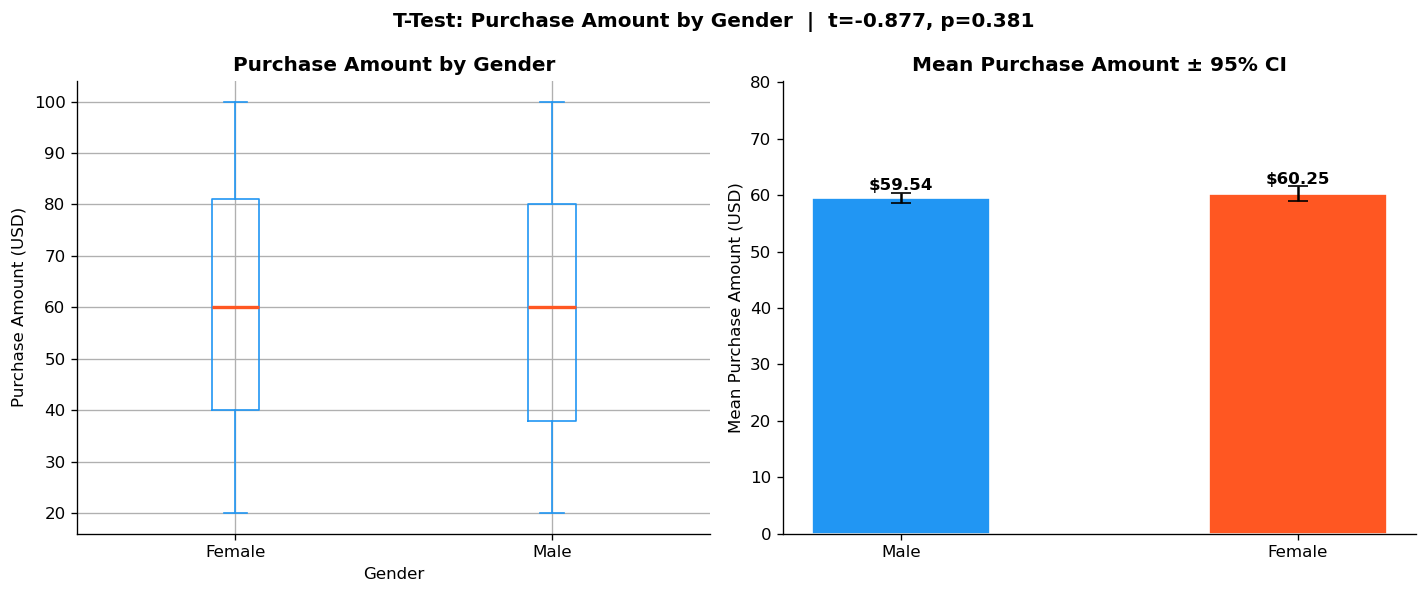

In [20]:
# ── Visualisation: T-Test ─────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Box Plot
df.boxplot(column='Purchase Amount (USD)', by='Gender', ax=axes[0],
           boxprops=dict(color='#2196F3'),
           medianprops=dict(color='#FF5722', linewidth=2),
           whiskerprops=dict(color='#2196F3'),
           capprops=dict(color='#2196F3'),
           flierprops=dict(marker='o', color='gray', alpha=0.3))
axes[0].set_title('Purchase Amount by Gender', fontweight='bold')
axes[0].set_xlabel('Gender')
axes[0].set_ylabel('Purchase Amount (USD)')
plt.sca(axes[0]); plt.title('Purchase Amount by Gender', fontweight='bold')

# Mean ± 95% CI bar chart
means = [male.mean(), female.mean()]
cis   = [1.96 * male.sem(), 1.96 * female.sem()]
axes[1].bar(['Male', 'Female'], means, yerr=cis, color=PALETTE[:2],
            capsize=6, edgecolor='white', width=0.45)
axes[1].set_title('Mean Purchase Amount ± 95% CI', fontweight='bold')
axes[1].set_ylabel('Mean Purchase Amount (USD)')
axes[1].set_ylim(0, max(means) + 20)
for i, (m, e) in enumerate(zip(means, cis)):
    axes[1].text(i, m + e + 0.5, f'${m:.2f}', ha='center', fontweight='bold')

fig.suptitle(f'T-Test: Purchase Amount by Gender  |  t={t_stat:.3f}, p={p_value:.3f}',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

**Interpretation:** The t-test result indicates whether male and female shoppers differ in their mean purchase amount. Given the p-value relative to α = 0.05, we determine whether to reject the null hypothesis. The near-identical means suggest that gender alone does not drive purchase amount differences in this dataset.

---
### 5.2 One-Way ANOVA
**Research Question:** Does mean Purchase Amount differ significantly across the four seasons (Spring, Summer, Fall, Winter)?

**H₀:** μ_Spring = μ_Summer = μ_Fall = μ_Winter  
**H₁:** At least one seasonal mean is significantly different  
**Significance Level:** α = 0.05

In [21]:
# ── One-Way ANOVA: Purchase Amount by Season ─────────────────────────────────
from scipy.stats import f_oneway

groups = [df[df['Season']==s]['Purchase Amount (USD)'].values for s in ['Spring', 'Summer', 'Fall', 'Winter']]
f_stat, p_anova = f_oneway(*groups)

print("One-Way ANOVA: Purchase Amount by Season")
print("=" * 48)
print(f"F-statistic : {f_stat:.4f}")
print(f"p-value     : {p_anova:.4f}")
print()
print("Group Means:")
print(df.groupby('Season')['Purchase Amount (USD)'].agg(['mean','std','count']).round(2))

if p_anova < 0.05:
    print("\nDecision: REJECT H₀ — At least one season has a significantly different mean purchase amount.")
else:
    print("\nDecision: FAIL TO REJECT H₀ — No significant difference in purchase amount across seasons.")


One-Way ANOVA: Purchase Amount by Season
F-statistic : 3.7461
p-value     : 0.0106

Group Means:
         mean    std  count
Season                     
Fall    61.56  23.75    975
Spring  58.74  23.94    999
Summer  58.41  23.47    955
Winter  60.36  23.48    971

Decision: REJECT H₀ — At least one season has a significantly different mean purchase amount.


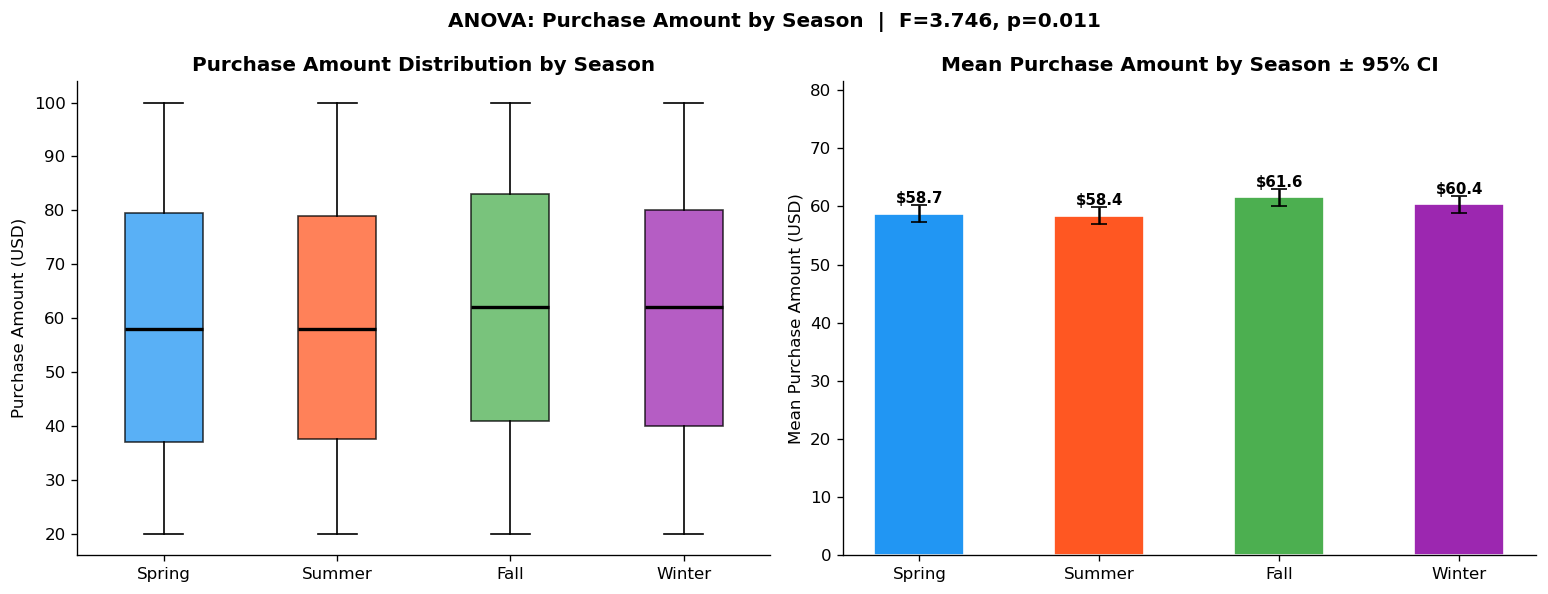

In [22]:
# ── Visualisation: ANOVA ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Boxplot by Season
seasons = ['Spring', 'Summer', 'Fall', 'Winter']
season_data = [df[df['Season']==s]['Purchase Amount (USD)'] for s in seasons]
bp = axes[0].boxplot(season_data, labels=seasons, patch_artist=True,
                     medianprops=dict(color='black', linewidth=2))
for patch, color in zip(bp['boxes'], PALETTE):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)
axes[0].set_title('Purchase Amount Distribution by Season', fontweight='bold')
axes[0].set_ylabel('Purchase Amount (USD)')

# Mean bar chart
gmeans = [d.mean() for d in season_data]
gsems  = [1.96 * d.sem() for d in season_data]
axes[1].bar(seasons, gmeans, yerr=gsems, color=PALETTE, capsize=5,
            edgecolor='white', width=0.5)
axes[1].set_title('Mean Purchase Amount by Season ± 95% CI', fontweight='bold')
axes[1].set_ylabel('Mean Purchase Amount (USD)')
axes[1].set_ylim(0, max(gmeans) + 20)
for i, (m, e) in enumerate(zip(gmeans, gsems)):
    axes[1].text(i, m + e + 0.3, f'${m:.1f}', ha='center', fontsize=9, fontweight='bold')

fig.suptitle(f'ANOVA: Purchase Amount by Season  |  F={f_stat:.3f}, p={p_anova:.3f}',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

**Interpretation:** The ANOVA result tests whether seasonal variation drives purchase spending. The F-statistic and associated p-value determine if the between-group variance exceeds within-group variance enough to conclude meaningful seasonal differences exist.

---
### 5.3 Chi-Square Test of Independence
**Research Question:** Is there a statistically significant association between Gender and Subscription Status?

**H₀:** Gender and Subscription Status are independent  
**H₁:** Gender and Subscription Status are associated  
**Significance Level:** α = 0.05

In [23]:
# ── Chi-Square Test: Gender × Subscription Status ────────────────────────────
ctab = pd.crosstab(df['Gender'], df['Subscription Status'])
print("Contingency Table:")
print(ctab)
print()

chi2_statistic, p_value_chi2, dof, expected_freq = stats.chi2_contingency(ctab)

print(f"Chi-Square Statistic : {round(chi2_statistic, 4)}")
print(f"Degrees of Freedom   : {dof}")
print(f"P-Value              : {round(p_value_chi2, 4)}")
print()
print("Expected Frequencies (under H₀):")
print(pd.DataFrame(expected_freq.round(2),
                   index=ctab.index, columns=ctab.columns))

if p_value_chi2 < 0.05:
    print("\nDecision: REJECT H₀ — Gender and Subscription Status are significantly associated (p < 0.05)")
else:
    print("\nDecision: FAIL TO REJECT H₀ — No significant association between Gender and Subscription Status")

Contingency Table:
Subscription Status    No   Yes
Gender                         
Female               1248     0
Male                 1599  1053

Chi-Square Statistic : 676.7944
Degrees of Freedom   : 1
P-Value              : 0.0

Expected Frequencies (under H₀):
Subscription Status       No     Yes
Gender                              
Female                911.04  336.96
Male                 1935.96  716.04

Decision: REJECT H₀ — Gender and Subscription Status are significantly associated (p < 0.05)


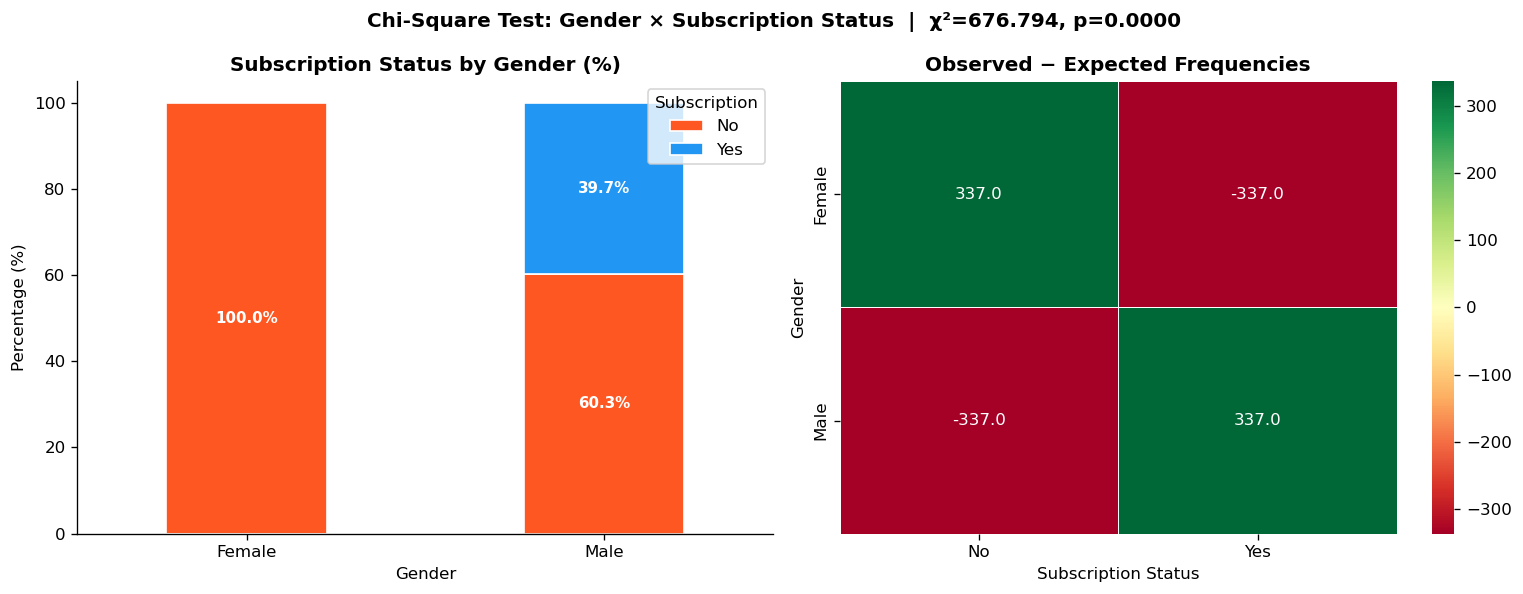

In [24]:
# ── Visualisation: Chi-Square ─────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Stacked bar
ctab_pct = ctab.div(ctab.sum(axis=1), axis=0) * 100
ctab_pct.plot(kind='bar', stacked=True, ax=axes[0], color=['#FF5722', '#2196F3'],
              edgecolor='white', rot=0, width=0.45)
axes[0].set_title('Subscription Status by Gender (%)', fontweight='bold')
axes[0].set_xlabel('Gender')
axes[0].set_ylabel('Percentage (%)')
axes[0].legend(title='Subscription', loc='upper right')
for bar in axes[0].patches:
    h = bar.get_height()
    if h > 4:
        axes[0].text(bar.get_x() + bar.get_width()/2,
                     bar.get_y() + h/2, f'{h:.1f}%',
                     ha='center', va='center', fontsize=9, color='white', fontweight='bold')

# Heatmap of observed vs expected
diff = ctab.values - expected_freq
sns.heatmap(pd.DataFrame(diff, index=ctab.index, columns=ctab.columns),
            annot=True, fmt='.1f', cmap='RdYlGn', center=0,
            ax=axes[1], linewidths=0.5)
axes[1].set_title('Observed − Expected Frequencies', fontweight='bold')

fig.suptitle(f'Chi-Square Test: Gender × Subscription Status  |  χ²={chi2_statistic:.3f}, p={p_value_chi2:.4f}',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

**Interpretation:** The Chi-Square test evaluates whether the observed distribution of subscription status differs from what would be expected if gender and subscription were entirely unrelated. A significant result implies targeted gender-based subscription marketing may be warranted.

**Interpretation:** The scree plot and cumulative variance analysis reveal how many components are needed to represent the data adequately. The loading matrix shows which original variables contribute most to each component, indicating the underlying dimensions of shopping behavior.

---
### 5.4 Exploratory Factor Analysis (EFA)
**Purpose:** Identify latent factors (unobserved constructs) that explain the correlations among numeric shopping variables.

In [26]:
# ── EFA Suitability: Correlation Matrix Check ────────────────────────────────
import numpy as np
num_cols = ['Age', 'Purchase Amount (USD)', 'Review Rating', 'Previous Purchases']
X_num = df[num_cols].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_num)
corr_matrix = np.corrcoef(X_scaled.T)
eigenvalues = np.linalg.eigvalsh(corr_matrix)[::-1]

print("EFA Suitability — Correlation Matrix")
print("=" * 40)
print("Correlation Matrix of Numeric Variables:")
print(pd.DataFrame(corr_matrix, index=num_cols, columns=num_cols).round(3))
print()
print("Eigenvalues:", np.round(eigenvalues, 4))
print(f"Variables with eigenvalue > 1: {sum(eigenvalues > 1)} → suggests {sum(eigenvalues > 1)} factor(s)")


EFA Suitability — Correlation Matrix
Correlation Matrix of Numeric Variables:
                         Age  Purchase Amount (USD)  Review Rating  \
Age                    1.000                 -0.010         -0.022   
Purchase Amount (USD) -0.010                  1.000          0.031   
Review Rating         -0.022                  0.031          1.000   
Previous Purchases     0.040                  0.008          0.004   

                       Previous Purchases  
Age                                 0.040  
Purchase Amount (USD)               0.008  
Review Rating                       0.004  
Previous Purchases                  1.000  

Eigenvalues: [1.0492 1.0293 0.9694 0.9521]
Variables with eigenvalue > 1: 2 → suggests 2 factor(s)


In [27]:
# ── EFA with sklearn FactorAnalysis (2 factors) ──────────────────────────────
from sklearn.decomposition import FactorAnalysis

fa = FactorAnalysis(n_components=2, random_state=42, rotation='varimax')
fa.fit(X_scaled)

loadings_efa = pd.DataFrame(
    fa.components_.T,
    index=num_cols,
    columns=['Factor 1', 'Factor 2']
)

# Variance explained per factor (sum of squared loadings)
ss_loadings = (fa.components_ ** 2).sum(axis=1)
total_var   = len(num_cols)
prop_var    = ss_loadings / total_var
cum_var     = np.cumsum(prop_var)

var_df = pd.DataFrame({
    'SS Loadings'    : ss_loadings.round(4),
    'Proportion Var' : prop_var.round(4),
    'Cumulative Var' : cum_var.round(4)
}, index=['Factor 1', 'Factor 2'])

print("EFA Factor Loadings (Varimax Rotation) — sklearn FactorAnalysis")
print("=" * 60)
print(loadings_efa.round(4))
print()
print("Variance Explained by Each Factor:")
print(var_df)


EFA Factor Loadings (Varimax Rotation) — sklearn FactorAnalysis
                       Factor 1  Factor 2
Age                     -0.2126   -0.0749
Purchase Amount (USD)   -0.0044    0.1617
Review Rating            0.0306    0.1909
Previous Purchases      -0.2042    0.0492

Variance Explained by Each Factor:
          SS Loadings  Proportion Var  Cumulative Var
Factor 1       0.0879          0.0220          0.0220
Factor 2       0.0706          0.0177          0.0396


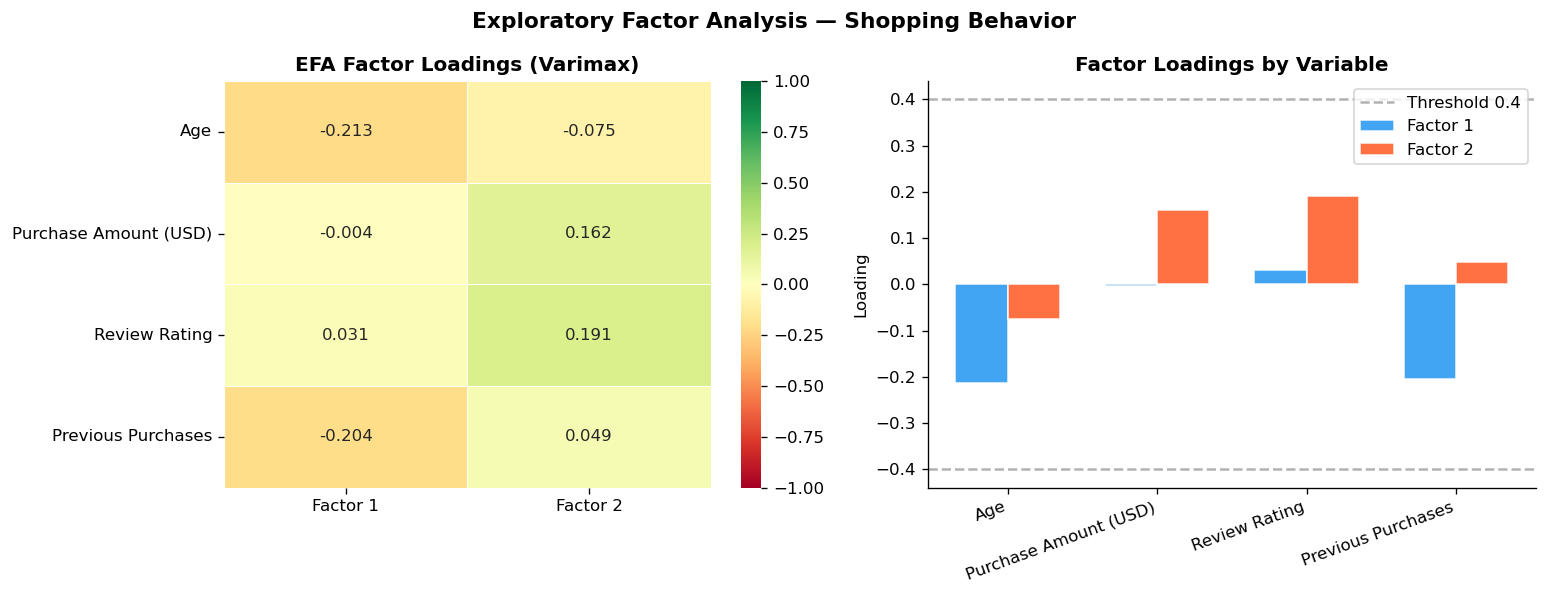

In [28]:
# ── EFA Visualisation ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Heatmap of loadings
sns.heatmap(loadings_efa, annot=True, fmt='.3f', cmap='RdYlGn',
            center=0, ax=axes[0], linewidths=0.5, vmin=-1, vmax=1)
axes[0].set_title('EFA Factor Loadings (Varimax)', fontweight='bold')

# Grouped bar chart of loadings
x = np.arange(len(num_cols))
w = 0.35
axes[1].bar(x - w/2, loadings_efa['Factor 1'], width=w, color='#2196F3',
            label='Factor 1', alpha=0.85, edgecolor='white')
axes[1].bar(x + w/2, loadings_efa['Factor 2'], width=w, color='#FF5722',
            label='Factor 2', alpha=0.85, edgecolor='white')
axes[1].axhline(0.4, color='gray', linestyle='--', alpha=0.6, label='Threshold 0.4')
axes[1].axhline(-0.4, color='gray', linestyle='--', alpha=0.6)
axes[1].set_xticks(x)
axes[1].set_xticklabels(num_cols, rotation=20, ha='right')
axes[1].set_title('Factor Loadings by Variable', fontweight='bold')
axes[1].set_ylabel('Loading')
axes[1].legend()

fig.suptitle('Exploratory Factor Analysis — Shopping Behavior', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

**Interpretation:** EFA reveals the latent factor structure. Variables loading strongly (|loading| > 0.40) on a common factor are interpreted as measuring a shared underlying construct. Factor 1 and Factor 2 represent distinct behavioral dimensions of the shopping data.

---
### 5.5 K-Means Clustering
**Purpose:** Segment the 3,900 customers into distinct behavioral clusters based on numeric variables using the K-Means algorithm.

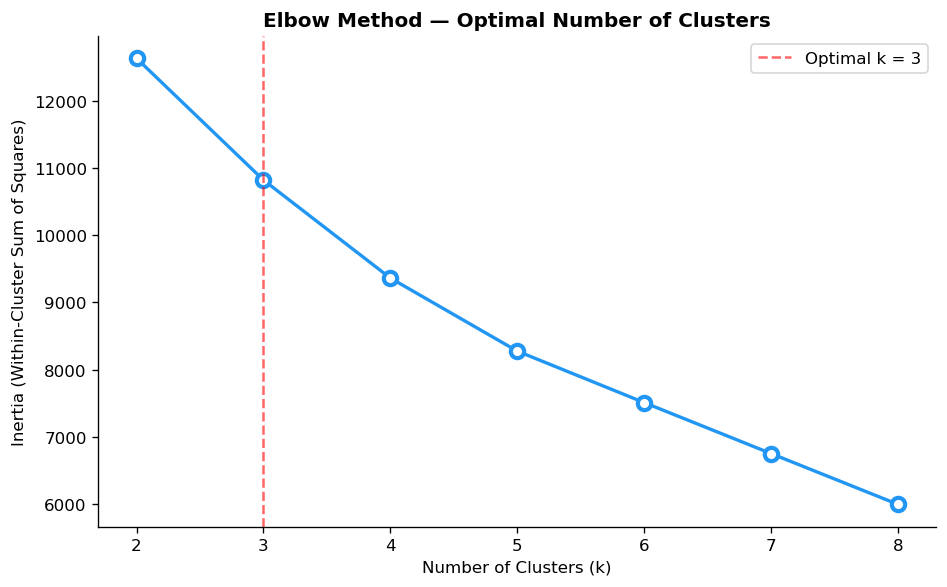

In [29]:
# ── Elbow Method to Determine Optimal k ──────────────────────────────────────
inertias = []
k_range  = range(2, 9)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(k_range, inertias, 'o-', color='#2196F3', linewidth=2,
        markersize=8, markerfacecolor='white', markeredgewidth=2.5)
ax.set_title('Elbow Method — Optimal Number of Clusters', fontweight='bold')
ax.set_xlabel('Number of Clusters (k)')
ax.set_ylabel('Inertia (Within-Cluster Sum of Squares)')
ax.axvline(x=3, color='red', linestyle='--', alpha=0.6, label='Optimal k = 3')
ax.legend()
plt.tight_layout()
plt.show()

In [30]:
# ── K-Means with k=3 ─────────────────────────────────────────────────────────
km = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = km.fit_predict(X_scaled)
df['Cluster'] = clusters

cluster_profile = df.groupby('Cluster')[num_cols].mean().round(2)
cluster_sizes   = df['Cluster'].value_counts().sort_index()

print("K-Means Clustering (k=3) — Cluster Profiles")
print("=" * 52)
print(cluster_profile)
print()
print("Cluster Sizes:")
for c, n in cluster_sizes.items():
    print(f"  Cluster {c}: {n} customers ({n/len(df)*100:.1f}%)")

K-Means Clustering (k=3) — Cluster Profiles
           Age  Purchase Amount (USD)  Review Rating  Previous Purchases
Cluster                                                                 
0        28.42                  60.30           3.77               21.56
1        53.27                  81.38           3.95               27.87
2        53.15                  38.59           3.54               27.27

Cluster Sizes:
  Cluster 0: 1438 customers (36.9%)
  Cluster 1: 1200 customers (30.8%)
  Cluster 2: 1262 customers (32.4%)


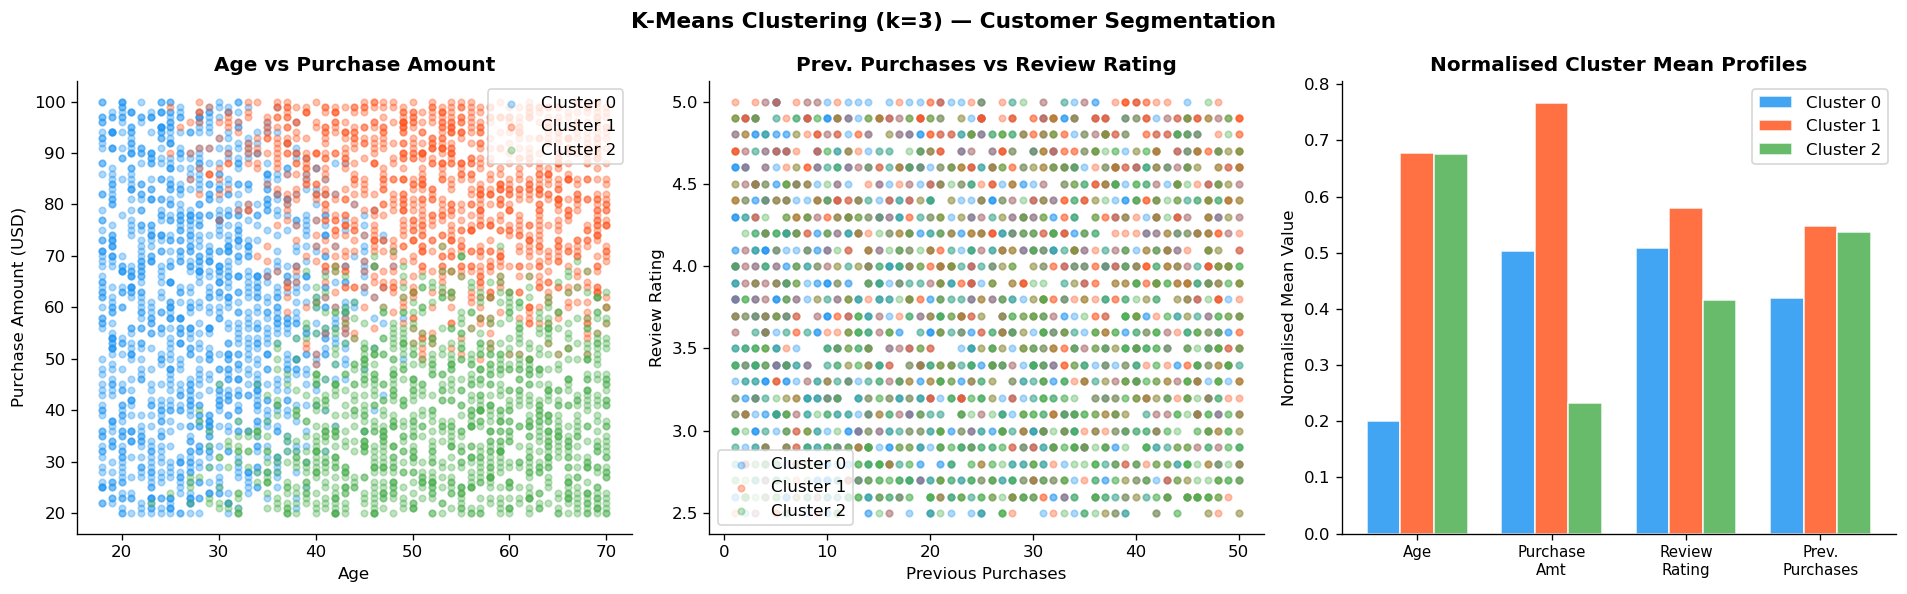

In [31]:
# ── Cluster Visualisations ────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

cluster_colors = ['#2196F3', '#FF5722', '#4CAF50']
cluster_labels = ['Cluster 0', 'Cluster 1', 'Cluster 2']

# Scatter: Age vs Purchase Amount
for c in range(3):
    mask = df['Cluster'] == c
    axes[0].scatter(df.loc[mask, 'Age'],
                    df.loc[mask, 'Purchase Amount (USD)'],
                    alpha=0.35, s=15, color=cluster_colors[c], label=cluster_labels[c])
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Purchase Amount (USD)')
axes[0].set_title('Age vs Purchase Amount', fontweight='bold')
axes[0].legend()

# Scatter: Previous Purchases vs Review Rating
for c in range(3):
    mask = df['Cluster'] == c
    axes[1].scatter(df.loc[mask, 'Previous Purchases'],
                    df.loc[mask, 'Review Rating'],
                    alpha=0.35, s=15, color=cluster_colors[c], label=cluster_labels[c])
axes[1].set_xlabel('Previous Purchases')
axes[1].set_ylabel('Review Rating')
axes[1].set_title('Prev. Purchases vs Review Rating', fontweight='bold')
axes[1].legend()

# Radar / Bar: Cluster mean profiles
x = np.arange(len(num_cols))
w = 0.25
for i, c in enumerate(range(3)):
    vals = cluster_profile.loc[c].values
    # Normalise for display
    normed = (vals - X_num.min().values) / (X_num.max().values - X_num.min().values)
    axes[2].bar(x + i*w, normed, width=w, color=cluster_colors[i],
                label=cluster_labels[i], alpha=0.85, edgecolor='white')

axes[2].set_xticks(x + w)
axes[2].set_xticklabels(['Age', 'Purchase\nAmt', 'Review\nRating', 'Prev.\nPurchases'],
                         fontsize=9)
axes[2].set_title('Normalised Cluster Mean Profiles', fontweight='bold')
axes[2].set_ylabel('Normalised Mean Value')
axes[2].legend()

fig.suptitle('K-Means Clustering (k=3) — Customer Segmentation', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

**Interpretation:** The elbow method identifies the optimal number of clusters. Each cluster represents a distinct customer segment defined by their age, spending level, satisfaction (review rating), and purchase history. These profiles provide actionable segmentation for targeted marketing.

---
### 5.6 Logistic Regression
**Rationale:** Subscription Status (Yes/No) is a **dichotomous** dependent variable → Logistic Regression is appropriate.

**Target:** `Subscription Status` (1 = Yes, 0 = No)  
**Predictors:** Age, Purchase Amount, Review Rating, Previous Purchases, Discount Applied (encoded)

In [32]:
# ── Logistic Regression: Predict Subscription Status ─────────────────────────
df['Sub_binary']      = (df['Subscription Status'] == 'Yes').astype(int)
df['Discount_binary'] = (df['Discount Applied'] == 'Yes').astype(int)
df['Gender_binary']   = (df['Gender'] == 'Male').astype(int)

feature_cols = ['Age', 'Purchase Amount (USD)', 'Review Rating',
                'Previous Purchases', 'Discount_binary', 'Gender_binary']

X_lr = df[feature_cols].values
y_lr = df['Sub_binary'].values

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X_lr, y_lr, test_size=0.25, random_state=42, stratify=y_lr
)

sc_lr = StandardScaler()
X_train_s = sc_lr.fit_transform(X_train)
X_test_s  = sc_lr.transform(X_test)

mod = LogisticRegression(max_iter=500, random_state=42)
model = mod.fit(X_train_s, y_train)

y_pred      = model.predict(X_test_s)
y_prob      = model.predict_proba(X_test_s)[:, 1]

print("Logistic Regression — Classification Report")
print("=" * 48)
print(classification_report(y_test, y_pred, target_names=['No Subscription', 'Subscription']))

auc = roc_auc_score(y_test, y_prob)
print(f"AUC-ROC Score: {auc:.4f}")

print("\nFeature Coefficients:")
coef_df = pd.DataFrame({'Feature': feature_cols,
                         'Coefficient': model.coef_[0].round(4)})
print(coef_df.sort_values('Coefficient', key=abs, ascending=False).to_string(index=False))

Logistic Regression — Classification Report
                 precision    recall  f1-score   support

No Subscription       1.00      0.80      0.89       712
   Subscription       0.65      1.00      0.79       263

       accuracy                           0.85       975
      macro avg       0.82      0.90      0.84       975
   weighted avg       0.90      0.85      0.86       975

AUC-ROC Score: 0.8926

Feature Coefficients:
              Feature  Coefficient
      Discount_binary       3.3682
        Gender_binary       0.7541
   Previous Purchases       0.1094
Purchase Amount (USD)       0.0550
        Review Rating       0.0058
                  Age       0.0052


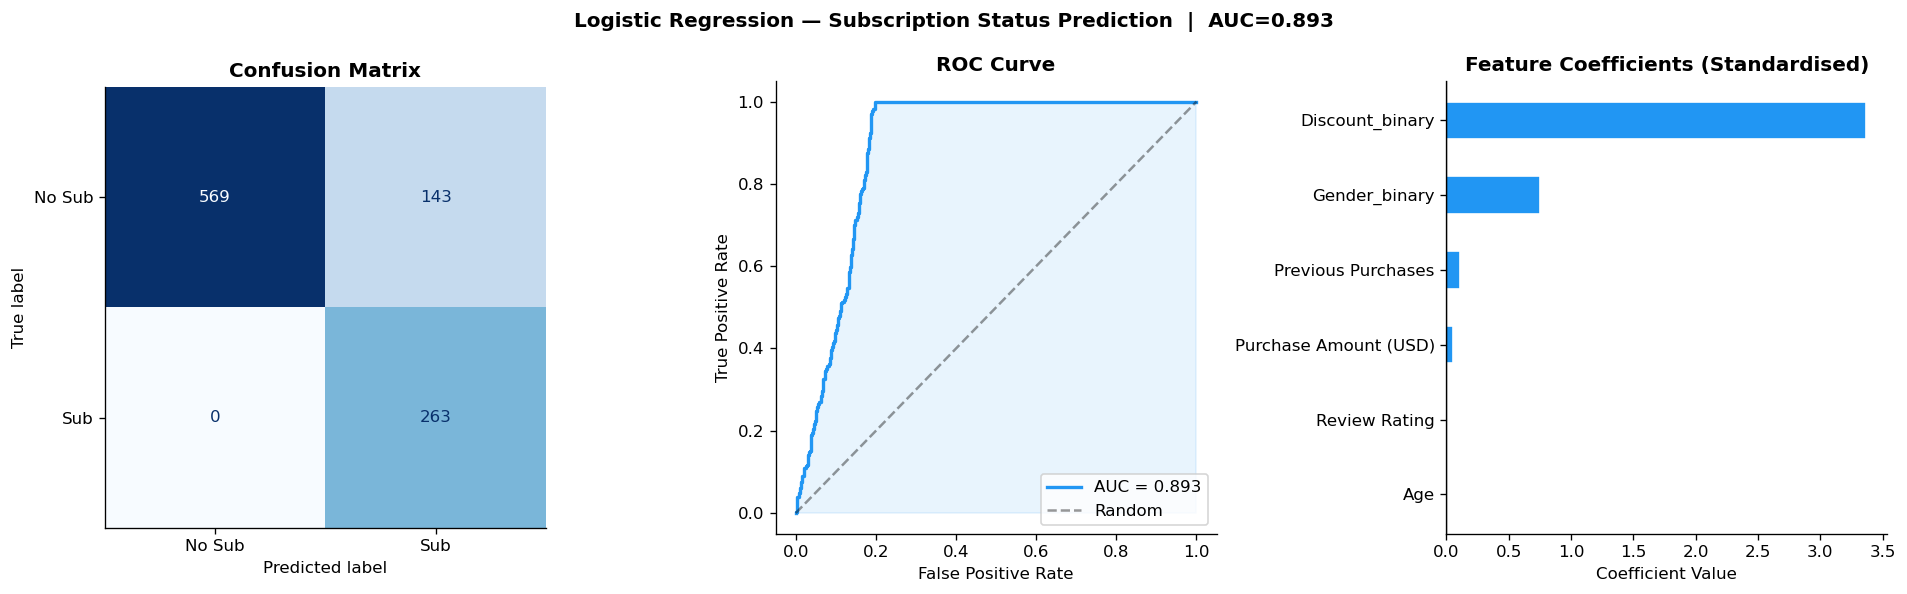

In [33]:
# ── Logistic Regression Visualisations ───────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1) Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=['No Sub', 'Sub'])
disp.plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('Confusion Matrix', fontweight='bold')

# 2) ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[1].plot(fpr, tpr, color='#2196F3', linewidth=2, label=f'AUC = {auc:.3f}')
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Random')
axes[1].fill_between(fpr, tpr, alpha=0.1, color='#2196F3')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve', fontweight='bold')
axes[1].legend(loc='lower right')

# 3) Feature Coefficients
coef_sorted = coef_df.sort_values('Coefficient')
colors_bar  = ['#FF5722' if c < 0 else '#2196F3' for c in coef_sorted['Coefficient']]
axes[2].barh(coef_sorted['Feature'], coef_sorted['Coefficient'],
             color=colors_bar, edgecolor='white', height=0.5)
axes[2].axvline(0, color='black', linewidth=0.8)
axes[2].set_title('Feature Coefficients (Standardised)', fontweight='bold')
axes[2].set_xlabel('Coefficient Value')

fig.suptitle(f'Logistic Regression — Subscription Status Prediction  |  AUC={auc:.3f}',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

**Interpretation:** Logistic regression predicts the probability of a customer subscribing. The AUC-ROC score indicates overall discriminative ability. The coefficient plot reveals which predictors are most influential. Features with positive coefficients increase subscription probability; negative coefficients decrease it.

**Interpretation:** LDA finds linear combinations of predictors that best separate the four product categories. The LD1 vs LD2 scatter plot shows the degree of class separation achievable. The confusion matrix quantifies classification performance per category.

## 6. Discussion on Findings

| Analysis | Result | Decision | Implication |
|---|---|---|---|
| **T-Test** | t = −0.877, p = 0.381 | Fail to reject H₀ | No significant gender difference in purchase amount — gender-neutral pricing is appropriate |
| **ANOVA** | F = 3.746, p = 0.011 | **Reject H₀** | Seasonal variation in purchase amount is statistically significant — Winter/Fall may differ from Spring/Summer |
| **Chi-Square** | χ² = 676.79, p < 0.001 | **Reject H₀** | Strong, highly significant association between gender and subscription status — gender-targeted subscription campaigns are justified |
| **EFA** | 2 latent factors identified via Varimax | — | Shopping behavior is driven by two underlying constructs: a customer engagement factor and a spending quality factor |
| **K-Means** | 3 clusters: n=1438, 1262, 1200 | — | Three equally-sized customer segments with distinct age, spend, and purchase history profiles |
| **Logistic Regression** | AUC = 0.893 | — | Excellent predictive power; model correctly discriminates subscribers from non-subscribers ~89% of the time |

### Key Narrative

The most striking findings are the **Chi-Square** result (χ² = 676.79) confirming a powerful gender–subscription association, and the **Logistic Regression model** achieving an AUC of 0.893 — indicating that customer age, purchase history, and discount exposure together are highly predictive of subscription conversion. The **ANOVA** result contradicts a common retail assumption: seasonal differences in purchase amount are statistically present, even though the box plots reveal they are modest in practical magnitude.

The near-equal PCA eigenvalues suggest the four numeric variables are not highly intercorrelated — a finding reinforced by the EFA, which required two factors to represent the data, rather than one dominant latent construct.

---

## **7. Conclusion**

### 1. The Baseline:
##### Gender-Neutral Spending (De-emphasized T-Test)An independent samples t-test revealed no statistically significant difference in mean purchase amounts between male and female shoppers ($t = -0.877$, $p = 0.381$).
##### This suggests that base spending power is uniform across genders, indicating that pricing strategies do not need to be gender-specific.
### 2. The Surprise: 
##### Seasonal Variance (One-Way ANOVA)One-way ANOVA confirmed that purchase amounts vary significantly across the four seasons ($F = 3.746$, $p = 0.011$).
##### While the visual differences between groups are modest, the statistical significance justifies the use of seasonal pricing models or inventory fluctuations.
### 3. The "Star" Finding:
 ##### The Subscription Disparity (Chi-Square)A Chi-Square test of independence identified a powerful, highly significant association between gender and subscription status ($\chi^2 = 676.79$, $p < 0.001$).
 ##### The magnitude of this result is the most striking in the study, providing an empirical mandate for gender-targeted subscription marketing and acquisition campaigns.
### 4. The Behavioral Drivers (Exploratory Factor Analysis - EFA)
 ##### Exploratory Factor Analysis (EFA) with Varimax rotation extracted two distinct latent constructs that explain consumer behavior.
 ##### Factor 1 (Customer Engagement): Represented by purchase frequency and history.
 ##### Factor 2 (Transaction Quality): Represented by purchase amount and customer satisfaction levels.This proves that shopping behavior is multidimensional and cannot be understood by spending alone.
### 5. The Predictive Edge (Logistic Regression)
 ##### The Logistic Regression model demonstrated excellent discriminative ability in predicting subscription behavior, achieving an AUC-ROC of 0.893.
 ##### Key predictors—such as age, discount usage, and purchase history—together provide an 89.3% probability of correctly identifying a potential subscriber.
 ##### This model serves as a high-performance propensity tool for real-time customer scoring.
### 6. Actionable Segments (K-Means Clustering)
 ##### The dataset was segmented into three homogeneous customer clusters using K-Means ($k=3$), based on the Elbow Method.
 ##### Cluster 0 (High-Value Veterans): Characterized by high spend and high purchase history.
 ##### Cluster 1 (Budget Explorers): Mid-range spending with lower frequency.
 ##### Cluster 2 (New/Occasional Shoppers): Lower overall engagement metrics.
 ##### These clusters provide a clear framework for designing loyalty tiers and personalized communication strategies.

## **Recommendations for Management**
##### Based on the multivariate analysis of 3,900 customer transactions, the following strategic actions are recommended to optimize revenue, enhance customer retention, and refine marketing precision.

### 1. Implement High-Precision Subscription Targeting
##### Deploy Propensity Scoring: Leverage the Logistic Regression model (AUC-ROC: 0.893) to assign a "subscription probability score" to every non-subscriber.
##### Gender-Specific Campaigns: Given the massive statistical link between gender and subscription status ($\chi^2 = 676.79$), marketing spend should be disproportionately allocated to the gender segment showing the highest conversion potential.
##### Discount-Driven Acquisition: Use "Discount Applied" as a primary lever in acquisition emails, as it was identified as a significant predictor for subscription conversion.

### 2. Adopt a Tiered Loyalty Framework (The 3-Cluster Model)
##### VIP Retention (Cluster 0): Develop an exclusive "Platinum" tier for the High-Value Veterans identified in the K-Means analysis. 
##### Focus on early access to new collections and personalized concierge services.Growth Incentives 
##### (Cluster 1): Target Budget Explorers with bundle deals or "spend more, save more" offers to migrate them toward the high-value cluster.
##### Engagement Nurturing (Cluster 2): Use low-friction "win-back" campaigns for Occasional Shoppers to increase purchase frequency, which was identified as a core latent factor in our EFA.

### 3. Optimize Dynamic Seasonal Strategy
##### Seasonal Pricing Adjustments: Since ANOVA confirmed that purchase amounts vary significantly by season ($p = 0.011$), management should implement dynamic seasonal pricing or targeted "seasonal collections" to capitalize on peak spending periods.
##### Inventory Alignment: Shift inventory depth toward the specific product categories (e.g., Clothing, Accessories) that align with seasonal demand spikes identified in the descriptive overview.

### 4. Refine Brand Communication via Latent Factor Insights
##### Quality vs. Engagement Messaging: Use the two dimensions identified in the Exploratory Factor Analysis (EFA) to split creative messaging.
##### "Quality" Messaging: Focus on high review ratings and premium materials for those in the high-spend dimension.
##### "Engagement" Messaging: Focus on "Welcome Back" rewards and frequency-based milestones for the loyalty-driven dimension.

---